# 01. How a decision tree chooses a split

A classification tree asks yes/no questions of the form *"is feature j ≤ threshold s?"*. At each node
it picks the (j, s) that makes the two child nodes as **pure** as possible.

For a node with share $p$ of class 1:
* **Gini impurity** $G = 1 - p^2 - (1-p)^2 = 2p(1-p)$, the chance two random rows disagree;
* **Entropy** $H = -p\log_2 p - (1-p)\log_2(1-p)$;
* **Misclassification** $E = \min(p, 1-p)$.

A split's quality is the impurity decrease
$\Delta = I(\text{parent}) - \frac{n_L}{n} I(L) - \frac{n_R}{n} I(R)$.

Target throughout: is a river's **phosphate class good or better?** (3,706 English rivers.)

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))
# a small, readable working set used throughout
F = ["up_stw_dwf_m3d_per_km2", "up_spill_hours_per_km2", "up_lc_urban", "up_lc_arable",
     "up_lc_improved_grass", "up_lc_seminatural", "up_area_km2", "local_n_private_sewage"]
d = t[t.phos_good.notna()].reset_index(drop=True)
X, y = d[F].to_numpy(float), d.phos_good.to_numpy(int)
groups = d.management_catchment.to_numpy()
print(X.shape, "share with good phosphate:", y.mean().round(3))

(3706, 8) share with good phosphate: 0.484


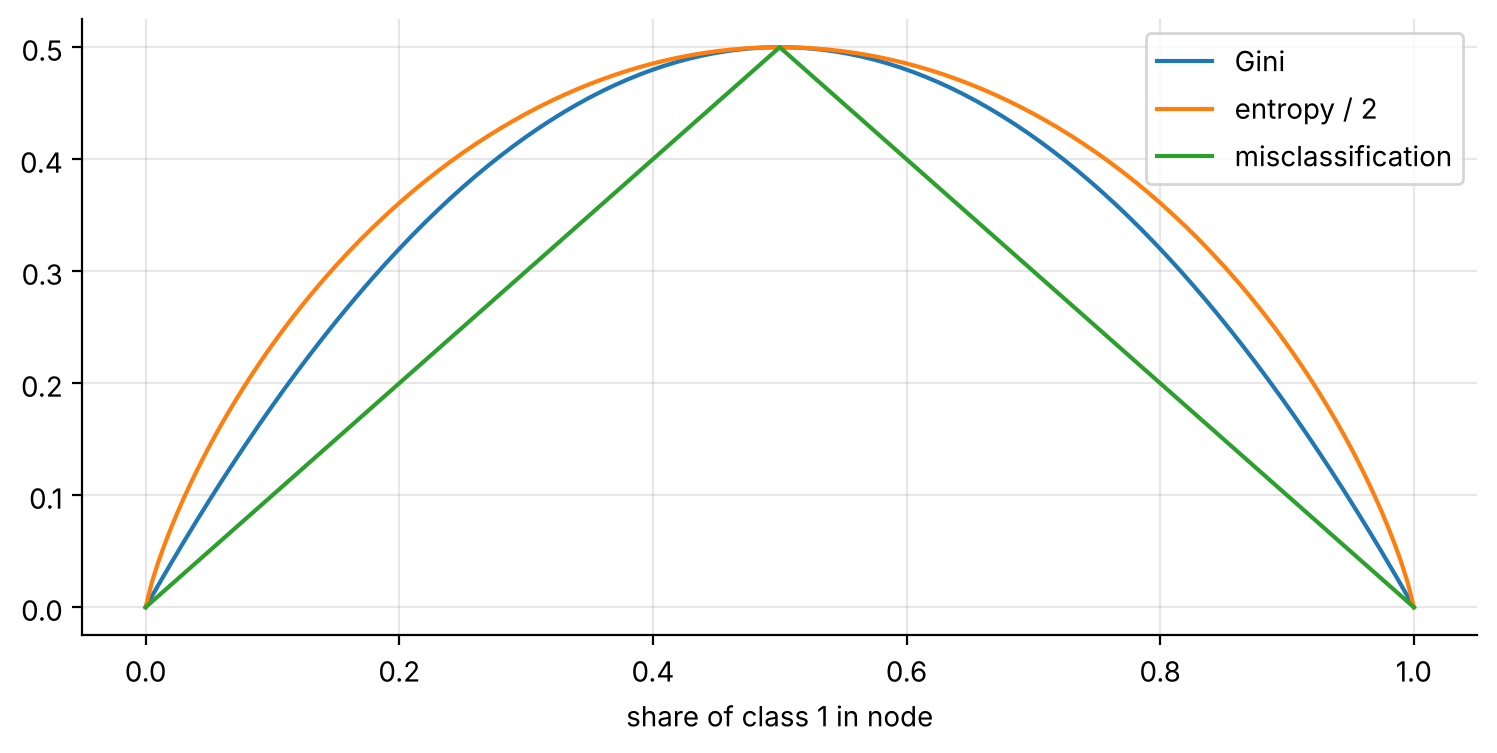

In [2]:
p = np.linspace(0, 1, 201)
plt.plot(p, 2 * p * (1 - p), label="Gini")
plt.plot(p, np.where((p > 0) & (p < 1), -(p * np.log2(p + 1e-12) + (1 - p) * np.log2(1 - p + 1e-12)), 0) / 2,
         label="entropy / 2")
plt.plot(p, np.minimum(p, 1 - p), label="misclassification")
plt.xlabel("share of class 1 in node"); plt.legend(); plt.show()

Gini and entropy are strictly concave, so any split that changes class shares reduces them.
Misclassification is piecewise linear and often reports zero gain for a useful split, which is why trees grow
with Gini or entropy and are only *evaluated* on error.

## Finding the best split from scratch

In [3]:
def gini(y):
    if len(y) == 0: return 0.0
    p = y.mean(); return 2 * p * (1 - p)

def best_split(x, y):
    """Scan every midpoint between sorted unique values; O(n log n) with cumulative counts."""
    o = np.argsort(x); xs, ys = x[o], y[o]
    n = len(y); c1 = np.cumsum(ys); nl = np.arange(1, n + 1)
    pl = c1 / nl; pr = (c1[-1] - c1) / np.maximum(n - nl, 1)
    gl, gr = 2 * pl * (1 - pl), 2 * pr * (1 - pr)
    w = gini(y) - (nl / n) * gl - ((n - nl) / n) * gr
    valid = np.r_[xs[1:] != xs[:-1], False]          # only between distinct values
    w[~valid] = -np.inf
    k = int(np.argmax(w))
    return (xs[k] + xs[k + 1]) / 2, w[k]

res = pd.DataFrame([(f, *best_split(X[:, j], y)) for j, f in enumerate(F)],
                   columns=["feature", "threshold", "gini_decrease"]).sort_values("gini_decrease", ascending=False)
res

,feature,threshold,gini_decrease
2,up_lc_urban,0.006378,0.078803
0,up_stw_dwf_m3d_per_km2,4.622769,0.065277
3,up_lc_arable,0.026085,0.059869
1,up_spill_hours_per_km2,0.056263,0.039174
5,up_lc_seminatural,0.444709,0.011181
7,local_n_private_sewage,1.500000,0.007236
4,up_lc_improved_grass,0.005038,0.006128
6,up_area_km2,136.498615,0.006062


In [4]:
from sklearn.tree import DecisionTreeClassifier
stump = DecisionTreeClassifier(max_depth=1).fit(X, y)
print("sklearn root:", F[stump.tree_.feature[0]], "<=", round(stump.tree_.threshold[0], 4))
print("ours        :", res.iloc[0].feature, "<=", round(res.iloc[0].threshold, 4))

sklearn root: up_lc_urban <= 0.0064
ours        : up_lc_urban <= 0.0064


The best single question is **whether there is any built-up land upstream** (more than about 0.6% of the
catchment): 86% of the 800 rivers below that threshold are good for phosphate, against 38% of the rest.
Close behind are sewage works effluent per km² and arable share. Our scan and scikit-learn agree exactly.

left : n=  803  P(good)=0.86
right: n= 2903  P(good)=0.38


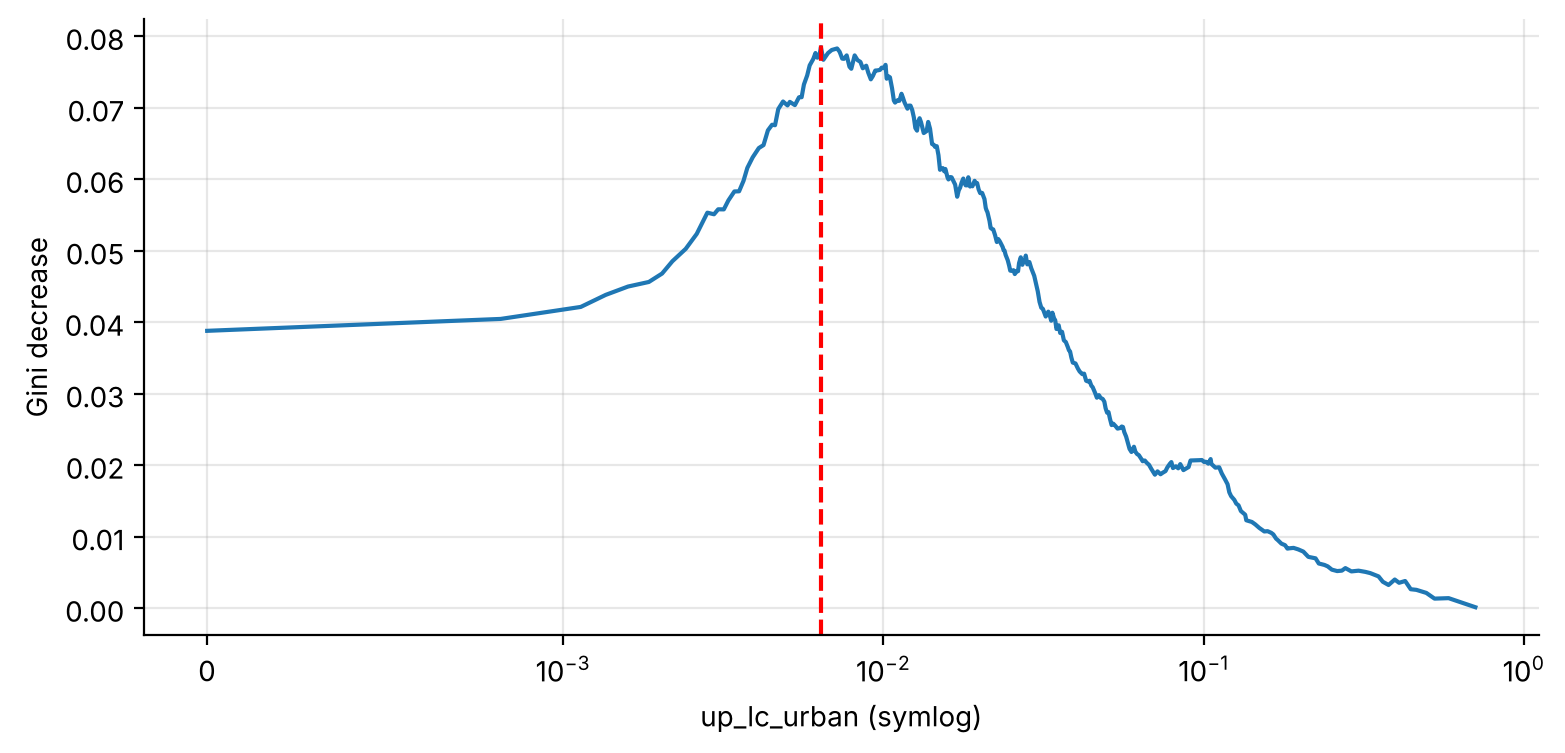

In [5]:
j = F.index(res.iloc[0].feature); s = res.iloc[0].threshold
left, right = y[X[:, j] <= s], y[X[:, j] > s]
print(f"left : n={len(left):5d}  P(good)={left.mean():.2f}")
print(f"right: n={len(right):5d}  P(good)={right.mean():.2f}")
xs = np.sort(np.unique(X[:, j]))[::10]
gains = [gini(y) - (X[:, j] <= v).mean() * gini(y[X[:, j] <= v]) - (X[:, j] > v).mean() * gini(y[X[:, j] > v]) for v in xs]
plt.plot(xs, gains); plt.xscale("symlog", linthresh=1e-3); plt.axvline(s, color="r", ls="--")
plt.xlabel(F[j] + " (symlog)"); plt.ylabel("Gini decrease"); plt.show()

**Things to notice**
* Trees only care about the **order** of a feature, so log transforms, scaling and outliers make no
  difference to the splits (unlike the logistic regression baseline).
* The gain curve is flat near its peak, so small changes in the data can move the threshold. That is the
  first sign of trees' instability (notebook 03).